### Sinkhorn Divergence — Optimal Transport validation

Optimal Transport (OT) introduces a distinct geometric perspective compared to previous distribution metrics. In a squared-Euclidean cost setting, shifting probability mass between nearby points is inexpensive, while moving it across large distances incurs higher costs. 

Previous embedding experiments demonstrated that displacement magnitude alone does not determine statistical detectability (e.g., Missing Cross-Channel Reference produced larger individual vector shifts than Entity Inconsistency, yet MMD and Energy Distance detected Entity Inconsistency much more reliably). OT provides a framework to analyze the geometry of this collective distributional shift.


#### OT limitations

Exact empirical Optimal Transport is computationally prohibitive and statistically unstable in high-dimensional spaces (such as the 384-dimensional semantic embeddings used here). To make the calculation smooth and tractable, entropic regularization is applied via the Sinkhorn algorithm. However, regularization is a computational tool, not a full solution to high-dimensional statistical bounds; Sinkhorn divergence must still be validated directly within the project's embedding space.


#### Entropic regularization and debiasing

Regularized transport costs $OT_\varepsilon(P,Q)$ introduce a self-similarity bias where $OT_\varepsilon(P,P) \neq 0$. To ensure identical distributions produce zero divergence, the debiased Sinkhorn formulation is used:

$$S_\varepsilon(P,Q) = OT_\varepsilon(P,Q) - \frac{1}{2}OT_\varepsilon(P,P) - \frac{1}{2}OT_\varepsilon(Q,Q)$$

This debiased statistic $S_\varepsilon(P,Q)$ serves as the primary evaluation metric.


#### Blur Parameter

In GeomLoss, the regularization scale is controlled by the `blur` parameter:
* **Low Blur:** Approaches unregularized OT but increases numerical and computational instability.
* **High Blur:** Produces smoother optimization but behaves similarly to kernel-based methods (MMD).

To prevent metric tuning against target results, `blur` is never selected by maximizing statistical power on defect experiments.


## Clean-only scale rule

All campaign embeddings are L2-normalized. The reference scale is defined strictly from clean representation geometry prior to defect testing:

$$\text{blur} = 0.10 \times \text{median clean pairwise distance}$$

This frozen factor ($0.10$) provides a reproducible, scale-aware parameterization. Any numerical instability or null calibration issues will be addressed using clean data and known-answer tests rather than defect-driven tuning.


In [1]:
%pip install "geomloss==0.3.1"

Note: you may need to restart the kernel to use updated packages.


In [3]:
from importlib.metadata import version
import torch

print("GeomLoss:", version("geomloss"))
print("PyTorch:", torch.__version__)
print("Device:", "mps" if torch.backends.mps.is_available() else "cpu")

GeomLoss: 0.3.1
PyTorch: 2.2.2
Device: cpu


In [4]:
import sys
print(sys.executable)

/Users/jessica/fidelity-metric-lab/.venv312/bin/python


In [12]:
import importlib
import numpy as np
import pandas as pd

import src.paths as paths
import src.io_utils as io_utils
import src.metrics as metrics

importlib.reload(paths)
importlib.reload(io_utils)
importlib.reload(metrics)

from src.paths import get_project_paths
from src.io_utils import load_embedding_conditions
from src.metrics import (
    median_pairwise_euclidean_scale,
    sinkhorn_divergence,
    sinkhorn_permutation_test,
    sinkhorn_paired_permutation_test
)

PATHS = get_project_paths()
DATA_DIR = PATHS["processed"]
RESULTS_DIR = PATHS["results"]
WEEK7_RESULTS_DIR = RESULTS_DIR / "week7"

WEEK7_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PATHS["root"])
print("Week 7 results:", WEEK7_RESULTS_DIR)

Project root: /Users/jessica/fidelity-metric-lab
Week 7 results: /Users/jessica/fidelity-metric-lab/results/week7


In [13]:
# load clean campaign embeddings 
entity_embeddings = load_embedding_conditions(
    DATA_DIR,
    prefix="entity"
)

X_clean = entity_embeddings["clean"]

print("Clean campaigns:", X_clean.shape)
print("Finite:", np.isfinite(X_clean).all())
print(
    "Mean norm:",
    np.linalg.norm(X_clean, axis=1).mean()
)

Clean campaigns: (300, 384)
Finite: True
Mean norm: 1.0


In [14]:
# define blur using clean data 
CLEAN_GEOMETRIC_SCALE = median_pairwise_euclidean_scale(
    X_clean
)

SINKHORN_BLUR_FRACTION = 0.10

CAMPAIGN_SINKHORN_BLUR = (
    SINKHORN_BLUR_FRACTION *
    CLEAN_GEOMETRIC_SCALE
)

print(
    "Median clean pairwise distance:",
    CLEAN_GEOMETRIC_SCALE
)

print(
    "Frozen campaign Sinkhorn blur:",
    CAMPAIGN_SINKHORN_BLUR
)

Median clean pairwise distance: 0.4371995243023655
Frozen campaign Sinkhorn blur: 0.043719952430236554


In [15]:
# identity check


In [16]:
X_identity = X_clean[:100]

identity_value = sinkhorn_divergence(
    X_identity,
    X_identity,
    blur=CAMPAIGN_SINKHORN_BLUR
)

print(
    "S(X, X):",
    f"{identity_value:.12e}"
)

S(X, X): 0.000000000000e+00


In [17]:
# synthetic known answer
rng = np.random.default_rng(42)

X_synthetic = rng.normal(
    size=(100, 2)
)

synthetic_scale = median_pairwise_euclidean_scale(
    X_synthetic
)

synthetic_blur = 0.10 * synthetic_scale

print("Synthetic scale:", synthetic_scale)
print("Synthetic blur:", synthetic_blur)

Synthetic scale: 1.4723582046728274
Synthetic blur: 0.14723582046728276


In [19]:
shift_levels = [0.0, 0.10, 0.25, 0.50, 1.00]

known_answer_records = []

for shift_fraction in shift_levels:
    Y = X_synthetic.copy()
    Y[:, 0] += shift_fraction * synthetic_scale

    value = sinkhorn_divergence(
        X_synthetic,
        Y,
        blur=synthetic_blur
    )

    known_answer_records.append({
        "shift_fraction": shift_fraction,
        "absolute_shift": shift_fraction * synthetic_scale,
        "sinkhorn_divergence": value
    })

sinkhorn_known_answer = pd.DataFrame(
    known_answer_records
)

display(sinkhorn_known_answer)

,shift_fraction,absolute_shift,sinkhorn_divergence
0,0.00,0.000000,0.000000
1,0.10,0.147236,0.010839
2,0.25,0.368090,0.067745
3,0.50,0.736179,0.270980
4,1.00,1.472358,1.083919


In [20]:
values = sinkhorn_known_answer[
    "sinkhorn_divergence"
].to_numpy()

print(
    "Monotonic:",
    np.all(np.diff(values) >= -1e-8)
)

Monotonic: True


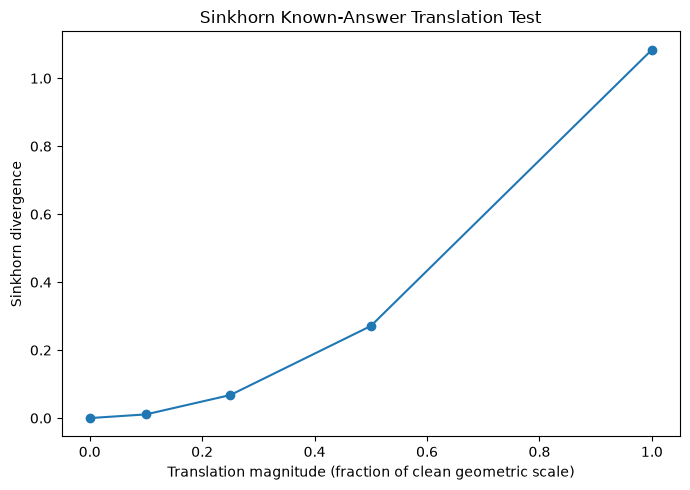

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    sinkhorn_known_answer["shift_fraction"],
    sinkhorn_known_answer["sinkhorn_divergence"],
    marker="o"
)

plt.xlabel("Translation magnitude (fraction of clean geometric scale)")
plt.ylabel("Sinkhorn divergence")
plt.title("Sinkhorn Known-Answer Translation Test")
plt.tight_layout()
plt.show()

In [22]:
# clean vs clean statistic 
rng = np.random.default_rng(42)

selected = rng.choice(
    len(X_clean),
    size=200,
    replace=False
)

P_clean = X_clean[selected[:100]]
Q_clean = X_clean[selected[100:]]

clean_stat = sinkhorn_divergence(
    P_clean,
    Q_clean,
    blur=CAMPAIGN_SINKHORN_BLUR
)

print(
    "Independent clean-vs-clean Sinkhorn:",
    clean_stat
)

Independent clean-vs-clean Sinkhorn: 0.045507416129112244


In [23]:
# runtime smoke test
rng = np.random.default_rng(42)

selected = rng.choice(
    len(X_clean),
    size=200,
    replace=False
)

P_clean = X_clean[selected[:100]]
Q_clean = X_clean[selected[100:]]

clean_stat = sinkhorn_divergence(
    P_clean,
    Q_clean,
    blur=CAMPAIGN_SINKHORN_BLUR
)

print(
    "Independent clean-vs-clean Sinkhorn:",
    clean_stat
)

Independent clean-vs-clean Sinkhorn: 0.045507416129112244


In [24]:
# preliminary null calibration
SINKHORN_NULL_REPS = 50
SINKHORN_PERMUTATIONS = 99
SINKHORN_ALPHA = 0.05
BASE_SEED = 42

In [25]:
from time import perf_counter

null_records = []
start = perf_counter()

for rep in range(SINKHORN_NULL_REPS):
    rng = np.random.default_rng(
        BASE_SEED + rep
    )

    selected = rng.choice(
        len(X_clean),
        size=200,
        replace=False
    )

    P = X_clean[selected[:100]]
    Q = X_clean[selected[100:]]

    result = sinkhorn_permutation_test(
        P,
        Q,
        blur=CAMPAIGN_SINKHORN_BLUR,
        n_permutations=SINKHORN_PERMUTATIONS,
        seed=10000 + rep,
        alpha=SINKHORN_ALPHA
    )

    null_records.append({
        "repetition": rep,
        "statistic": result["statistic"],
        "p_value": result["p_value"],
        "reject": result["reject"]
    })

    if (rep + 1) % 10 == 0:
        print(
            f"Completed {rep + 1}/"
            f"{SINKHORN_NULL_REPS}"
        )

sinkhorn_null_runtime = (
    perf_counter() - start
)

sinkhorn_null_results = pd.DataFrame(
    null_records
)

print(
    "Runtime:",
    round(sinkhorn_null_runtime, 2),
    "seconds"
)

Completed 10/50
Completed 20/50
Completed 30/50
Completed 40/50
Completed 50/50
Runtime: 102.04 seconds


In [26]:
sinkhorn_null_summary = pd.DataFrame([{
    "repetitions": len(sinkhorn_null_results),
    "rejections": int(
        sinkhorn_null_results["reject"].sum()
    ),
    "type_I_error": sinkhorn_null_results[
        "reject"
    ].mean(),
    "mean_p_value": sinkhorn_null_results[
        "p_value"
    ].mean(),
    "median_p_value": sinkhorn_null_results[
        "p_value"
    ].median(),
    "mean_statistic": sinkhorn_null_results[
        "statistic"
    ].mean(),
    "std_statistic": sinkhorn_null_results[
        "statistic"
    ].std()
}])

display(sinkhorn_null_summary)

,repetitions,rejections,type_I_error,mean_p_value,median_p_value,mean_statistic,std_statistic
0,50,2,0.04,0.497,0.47,0.04564,0.00122


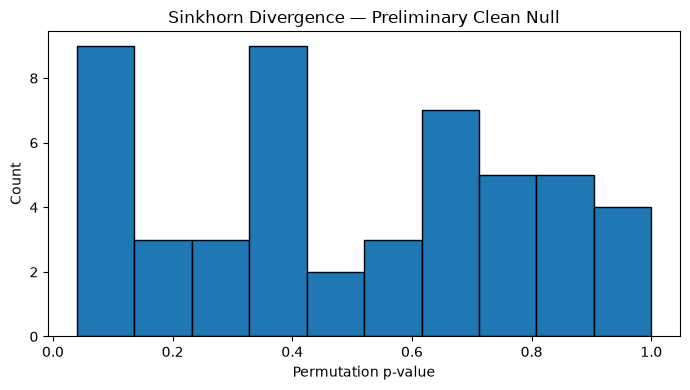

In [27]:
plt.figure(figsize=(7, 4))

plt.hist(
    sinkhorn_null_results["p_value"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Permutation p-value")
plt.ylabel("Count")
plt.title("Sinkhorn Divergence — Preliminary Clean Null")
plt.tight_layout()
plt.show()

In [28]:
sinkhorn_known_answer.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_known_answer.csv",
    index=False
)

sinkhorn_null_results.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_preliminary_null_runs.csv",
    index=False
)

sinkhorn_null_summary.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_preliminary_null_summary.csv",
    index=False
)

print("Sinkhorn validation outputs saved.")

Sinkhorn validation outputs saved.


In [29]:
# save config
import json
from importlib.metadata import version

sinkhorn_config = {
    "library": "geomloss",
    "geomloss_version": version("geomloss"),
    "representation": "campaign_semantic_embeddings",
    "embedding_dimension": 384,
    "normalized_embeddings": True,
    "loss": "sinkhorn",
    "p": 2,
    "debias": True,
    "backend": "tensorized",
    "device": "cpu",
    "clean_scale_rule": "median pairwise Euclidean distance",
    "clean_geometric_scale": CLEAN_GEOMETRIC_SCALE,
    "blur_fraction": SINKHORN_BLUR_FRACTION,
    "blur": CAMPAIGN_SINKHORN_BLUR,
    "preliminary_null_repetitions": SINKHORN_NULL_REPS,
    "preliminary_null_permutations": SINKHORN_PERMUTATIONS,
    "alpha": SINKHORN_ALPHA
}

with open(
    WEEK7_RESULTS_DIR /
    "sinkhorn_campaign_configuration.json",
    "w"
) as f:
    json.dump(sinkhorn_config, f, indent=4)

print("Sinkhorn configuration saved.")

Sinkhorn configuration saved.


In [30]:
# indeoendent clean vs clean experiment
rng = np.random.default_rng(42)

selected = rng.choice(
    len(X_clean),
    size=200,
    replace=False
)

P_clean = X_clean[selected[:100]]
Q_clean = X_clean[selected[100:]]

clean_stat = sinkhorn_divergence(
    P_clean,
    Q_clean,
    blur=CAMPAIGN_SINKHORN_BLUR
)

print(
    "Independent clean-vs-clean Sinkhorn:",
    clean_stat
)

Independent clean-vs-clean Sinkhorn: 0.045507416129112244


In [31]:
# runtime smoke test
from time import perf_counter

start = perf_counter()

smoke_result = sinkhorn_permutation_test(
    P_clean,
    Q_clean,
    blur=CAMPAIGN_SINKHORN_BLUR,
    n_permutations=20,
    seed=42,
    alpha=0.05
)

smoke_runtime = perf_counter() - start

print(smoke_result)
print(
    "20-permutation runtime:",
    round(smoke_runtime, 2),
    "seconds"
)

print(
    "Estimated 100-permutation runtime:",
    round(smoke_runtime * 5, 2),
    "seconds"
)

{'statistic': 0.045507416129112244, 'p_value': 0.42857142857142855, 'reject': False, 'null_mean': 0.04559994377195835, 'null_std': 0.0010974806360112533}
20-permutation runtime: 1.28 seconds
Estimated 100-permutation runtime: 6.38 seconds


In [32]:
# null calibration 
SINKHORN_FORMAL_NULL_REPS = 200
SINKHORN_FORMAL_PERMUTATIONS = 100
SINKHORN_ALPHA = 0.05
BASE_SEED = 42


In [33]:
from time import perf_counter

formal_null_records = []
start = perf_counter()

for rep in range(SINKHORN_FORMAL_NULL_REPS):
    rng = np.random.default_rng(BASE_SEED + rep)

    selected = rng.choice(
        len(X_clean),
        size=200,
        replace=False
    )

    P = X_clean[selected[:100]]
    Q = X_clean[selected[100:]]

    result = sinkhorn_permutation_test(
        P,
        Q,
        blur=CAMPAIGN_SINKHORN_BLUR,
        n_permutations=SINKHORN_FORMAL_PERMUTATIONS,
        seed=10000 + rep,
        alpha=SINKHORN_ALPHA
    )

    formal_null_records.append({
        "repetition": rep,
        "statistic": result["statistic"],
        "p_value": result["p_value"],
        "reject": result["reject"],
        "null_mean": result["null_mean"],
        "null_std": result["null_std"]
    })

    if (rep + 1) % 20 == 0:
        print(
            f"Completed {rep + 1}/"
            f"{SINKHORN_FORMAL_NULL_REPS}"
        )

formal_null_runtime = perf_counter() - start

sinkhorn_formal_null = pd.DataFrame(
    formal_null_records
)

print(
    "Runtime:",
    round(formal_null_runtime, 2),
    "seconds"
)

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Runtime: 421.15 seconds


In [34]:
sinkhorn_formal_null_summary = pd.DataFrame([{
    "repetitions": len(sinkhorn_formal_null),
    "rejections": int(
        sinkhorn_formal_null["reject"].sum()
    ),
    "type_I_error": sinkhorn_formal_null[
        "reject"
    ].mean(),
    "mean_p_value": sinkhorn_formal_null[
        "p_value"
    ].mean(),
    "median_p_value": sinkhorn_formal_null[
        "p_value"
    ].median(),
    "mean_statistic": sinkhorn_formal_null[
        "statistic"
    ].mean(),
    "std_statistic": sinkhorn_formal_null[
        "statistic"
    ].std(),
    "mean_perm_null": sinkhorn_formal_null[
        "null_mean"
    ].mean()
}])

display(sinkhorn_formal_null_summary)

,repetitions,rejections,type_I_error,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_perm_null
0,200,10,0.05,0.522178,0.529703,0.045498,0.001159,0.045546


In [35]:
print("Mean observed statistic:", sinkhorn_formal_null["statistic"].mean())

print("Mean permutation-null statistic:", sinkhorn_formal_null["null_mean"].mean())

print("Difference:", sinkhorn_formal_null["statistic"].mean() -  sinkhorn_formal_null[  "null_mean"].mean())

Mean observed statistic: 0.0454980793595314
Mean permutation-null statistic: 0.04554641302321106
Difference: -4.833366367965747e-05


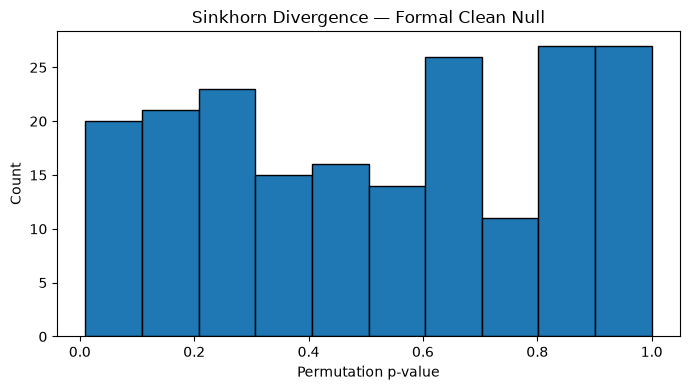

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.hist(
    sinkhorn_formal_null["p_value"],
    bins=10,
    edgecolor="black"
)
plt.xlabel("Permutation p-value")
plt.ylabel("Count")
plt.title("Sinkhorn Divergence — Formal Clean Null")
plt.tight_layout()
plt.show()

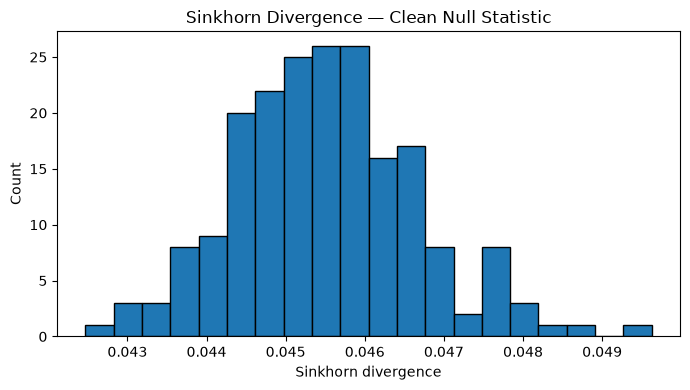

In [37]:
plt.figure(figsize=(7, 4))
plt.hist(
    sinkhorn_formal_null["statistic"],
    bins=20,
    edgecolor="black"
)
plt.xlabel("Sinkhorn divergence")
plt.ylabel("Count")
plt.title("Sinkhorn Divergence — Clean Null Statistic")
plt.tight_layout()
plt.show()

In [38]:
sinkhorn_formal_null.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_formal_null_runs.csv",
    index=False
)

sinkhorn_formal_null_summary.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_formal_null_summary.csv",
    index=False
)

print("Formal Sinkhorn null calibration saved.")

Formal Sinkhorn null calibration saved.


In [39]:
sinkhorn_config.update({
    "formal_null_repetitions":
        SINKHORN_FORMAL_NULL_REPS,
    "formal_null_permutations":
        SINKHORN_FORMAL_PERMUTATIONS,
    "formal_null_sample_size_per_group": 100
})

with open(
    WEEK7_RESULTS_DIR /
    "sinkhorn_campaign_configuration.json",
    "w"
) as f:
    json.dump(sinkhorn_config, f, indent=4)

print("Sinkhorn configuration updated.")

Sinkhorn configuration updated.


**Final campaign level configuration**

Representation: MiniLM campaign embeddings

Dimension: 384

p: 2

Debiased Sinkhorn: True

Backend: tensorized

Device: CPU

Blur rule: 0.10 × median clean pairwise distance

Frozen blur: 0.043719952430236554

Alpha: 0.05

Permutations: 100

Repetitions: 200

Pairs per repetition: 100

##### Entity inconsistency 

In [40]:
import src.io_utils as io_utils
import src.metrics as metrics

importlib.reload(io_utils)
importlib.reload(metrics)

from src.io_utils import (
    load_embedding_conditions,
    load_id_file,
    load_affected_ids_by_severity
)

from src.metrics import sinkhorn_paired_permutation_test

In [41]:
# fixed configuration 
ENTITY_REPS = 200
ENTITY_N_PAIRS = 100
ENTITY_PERMUTATIONS = 100
ENTITY_ALPHA = 0.05
ENTITY_SEVERITIES = [0.10, 0.30, 0.60]

ENTITY_SAMPLE_BASE_SEED = 42
ENTITY_TEST_BASE_SEED = 10000

print("Repetitions:", ENTITY_REPS)
print("Pairs per repetition:", ENTITY_N_PAIRS)
print("Permutations:", ENTITY_PERMUTATIONS)
print("Severities:", ENTITY_SEVERITIES)
print("Frozen blur:", CAMPAIGN_SINKHORN_BLUR)

Repetitions: 200
Pairs per repetition: 100
Permutations: 100
Severities: [0.1, 0.3, 0.6]
Frozen blur: 0.043719952430236554


In [43]:
# load entity embeddings 
entity_embeddings = load_embedding_conditions(
    DATA_DIR,
    prefix="entity",
    severities=(10, 30, 60))

entity_ids = load_id_file(
    DATA_DIR,
    "entity_embedding_campaign_ids.csv",
    id_column="campaign_id")

print("Clean:", entity_embeddings["clean"].shape)

for severity in ENTITY_SEVERITIES:
    print(
        f"{severity:.0%}:",
        entity_embeddings[severity].shape)

print("IDs:", len(entity_ids))

Clean: (300, 384)
10%: (300, 384)
30%: (300, 384)
60%: (300, 384)
IDs: 300


In [ ]:
# alignment validation 
X_entity_clean = entity_embeddings["clean"]

assert len(entity_ids) == len(X_entity_clean)
assert len(set(entity_ids)) == len(entity_ids)

for severity in ENTITY_SEVERITIES:
    X_def = entity_embeddings[severity]

    assert X_def.shape == X_entity_clean.shape
    assert np.isfinite(X_def).all()

print("Entity embedding alignment passed.")

Entity embedding alignment passed.


In [45]:
# norm validation
for condition, X in entity_embeddings.items():
    norms = np.linalg.norm(X, axis=1)

    print(
        condition,
        "| mean norm =",
        round(norms.mean(), 6),
        "| min =",
        round(norms.min(), 6),
        "| max =",
        round(norms.max(), 6)
    )

clean | mean norm = 1.0 | min = 1.0 | max = 1.0
0.1 | mean norm = 1.0 | min = 1.0 | max = 1.0
0.3 | mean norm = 1.0 | min = 1.0 | max = 1.0
0.6 | mean norm = 1.0 | min = 1.0 | max = 1.0


In [46]:
# load affected ids
entity_affected = load_affected_ids_by_severity(
    DATA_DIR / "entity_inconsistency_affected_campaign_ids.csv",
    id_column="campaign_id"
)

for severity in ENTITY_SEVERITIES:
    print(
        f"{severity:.0%}",
        "| affected campaigns =",
        len(entity_affected[severity])
    )

10% | affected campaigns = 30
30% | affected campaigns = 90
60% | affected campaigns = 180


In [47]:
# confirm nesting 
affected_10 = set(entity_affected[0.10])
affected_30 = set(entity_affected[0.30])
affected_60 = set(entity_affected[0.60])

print("10 ⊆ 30:", affected_10.issubset(affected_30))
print("30 ⊆ 60:", affected_30.issubset(affected_60))

assert affected_10.issubset(affected_30)
assert affected_30.issubset(affected_60)

10 ⊆ 30: True
30 ⊆ 60: True


In [48]:
# 1 rep smoke test 
rng = np.random.default_rng(ENTITY_SAMPLE_BASE_SEED)

sample_idx = rng.choice(
    len(entity_ids),
    size=ENTITY_N_PAIRS,
    replace=False
)

P_smoke = X_entity_clean[sample_idx]
Q_smoke = entity_embeddings[0.10][sample_idx]

start = perf_counter()

entity_smoke = sinkhorn_paired_permutation_test(
    P_smoke,
    Q_smoke,
    blur=CAMPAIGN_SINKHORN_BLUR,
    n_permutations=ENTITY_PERMUTATIONS,
    seed=ENTITY_TEST_BASE_SEED,
    alpha=ENTITY_ALPHA
)

smoke_runtime = perf_counter() - start

print(entity_smoke)
print("Runtime:", round(smoke_runtime, 2), "seconds")

{'statistic': 0.00024108665820676833, 'p_value': 0.039603960396039604, 'reject': True, 'null_mean': 0.0002410865826823283, 'null_std': 3.9942025240713486e-11}
Runtime: 4.64 seconds


In [49]:
# full entity experiment
entity_sinkhorn_records = []

start = perf_counter()

for rep in range(ENTITY_REPS):

    rng = np.random.default_rng(
        ENTITY_SAMPLE_BASE_SEED + rep
    )

    sample_idx = rng.choice(
        len(entity_ids),
        size=ENTITY_N_PAIRS,
        replace=False
    )

    sampled_ids = np.asarray(entity_ids)[sample_idx]

    P = X_entity_clean[sample_idx]

    for severity in ENTITY_SEVERITIES:

        Q = entity_embeddings[severity][sample_idx]

        affected_set = set(
            entity_affected[severity]
        )

        n_affected = sum(
            campaign_id in affected_set
            for campaign_id in sampled_ids
        )

        result = sinkhorn_paired_permutation_test(
            P,
            Q,
            blur=CAMPAIGN_SINKHORN_BLUR,
            n_permutations=ENTITY_PERMUTATIONS,
            seed=ENTITY_TEST_BASE_SEED + rep,
            alpha=ENTITY_ALPHA
        )

        entity_sinkhorn_records.append({
            "repetition": rep,
            "severity": severity,
            "n_pairs": ENTITY_N_PAIRS,
            "n_affected": n_affected,
            "sample_affected_rate":
                n_affected / ENTITY_N_PAIRS,
            "statistic": result["statistic"],
            "p_value": result["p_value"],
            "reject": result["reject"],
            "null_mean": result["null_mean"],
            "null_std": result["null_std"]
        })

    if (rep + 1) % 20 == 0:
        elapsed = perf_counter() - start

        print(
            f"Completed {rep + 1}/{ENTITY_REPS}",
            "| elapsed:",
            round(elapsed / 60, 1),
            "min"
        )

entity_sinkhorn_runtime = perf_counter() - start

entity_sinkhorn_runs = pd.DataFrame(
    entity_sinkhorn_records
)

print("\nRows:", len(entity_sinkhorn_runs))
print(
    "Expected:",
    ENTITY_REPS * len(ENTITY_SEVERITIES)
)
print(
    "Total runtime:",
    round(entity_sinkhorn_runtime / 60, 2),
    "minutes"
)

Completed 20/200 | elapsed: 2.2 min
Completed 40/200 | elapsed: 4.6 min
Completed 60/200 | elapsed: 6.3 min
Completed 80/200 | elapsed: 7.6 min
Completed 100/200 | elapsed: 8.5 min
Completed 120/200 | elapsed: 9.4 min
Completed 140/200 | elapsed: 10.6 min
Completed 160/200 | elapsed: 11.6 min
Completed 180/200 | elapsed: 12.9 min
Completed 200/200 | elapsed: 14.0 min

Rows: 600
Expected: 600
Total runtime: 14.04 minutes


In [50]:
# confirm effective prevalence within the samples 
entity_prevalence_check = (
    entity_sinkhorn_runs
    .groupby("severity")
    .agg(
        mean_affected=("n_affected", "mean"),
        std_affected=("n_affected", "std"),
        min_affected=("n_affected", "min"),
        max_affected=("n_affected", "max"),
        mean_sample_rate=(
            "sample_affected_rate",
            "mean"
        )
    )
    .reset_index()
)

display(entity_prevalence_check)

,severity,mean_affected,std_affected,min_affected,max_affected,mean_sample_rate
0,0.1,9.975,2.297995,2,16,0.09975
1,0.3,29.965,3.812671,18,38,0.29965
2,0.6,59.980,3.909735,48,69,0.59980


In [51]:
# power summary 
entity_sinkhorn_summary = (
    entity_sinkhorn_runs
    .groupby("severity")
    .agg(
        repetitions=("reject", "size"),
        rejections=("reject", "sum"),
        power=("reject", "mean"),
        mean_p_value=("p_value", "mean"),
        median_p_value=("p_value", "median"),
        mean_statistic=("statistic", "mean"),
        std_statistic=("statistic", "std"),
        mean_null_statistic=("null_mean", "mean"),
        mean_affected=("n_affected", "mean"),
        mean_sample_affected_rate=(
            "sample_affected_rate",
            "mean"
        )
    )
    .reset_index()
)

display(entity_sinkhorn_summary)

,severity,repetitions,rejections,power,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_null_statistic,mean_affected,mean_sample_affected_rate
0,0.1,200,9,0.045,0.525644,0.504950,0.000230,0.000070,0.000230,9.975,0.09975
1,0.3,200,5,0.025,0.551634,0.539604,0.000646,0.000152,0.000646,29.965,0.29965
2,0.6,200,18,0.090,0.393168,0.326733,0.001198,0.000169,0.001198,59.980,0.59980


In [52]:
for _, row in entity_sinkhorn_summary.iterrows():

    print(
        f"{row['severity']:.0%}",
        "| power =",
        f"{row['power']:.3f}",
        "| mean statistic =",
        f"{row['mean_statistic']:.6f}",
        "| mean p =",
        f"{row['mean_p_value']:.4f}",
        "| mean affected =",
        f"{row['mean_affected']:.1f}"
    )

10% | power = 0.045 | mean statistic = 0.000230 | mean p = 0.5256 | mean affected = 10.0
30% | power = 0.025 | mean statistic = 0.000646 | mean p = 0.5516 | mean affected = 30.0
60% | power = 0.090 | mean statistic = 0.001198 | mean p = 0.3932 | mean affected = 60.0


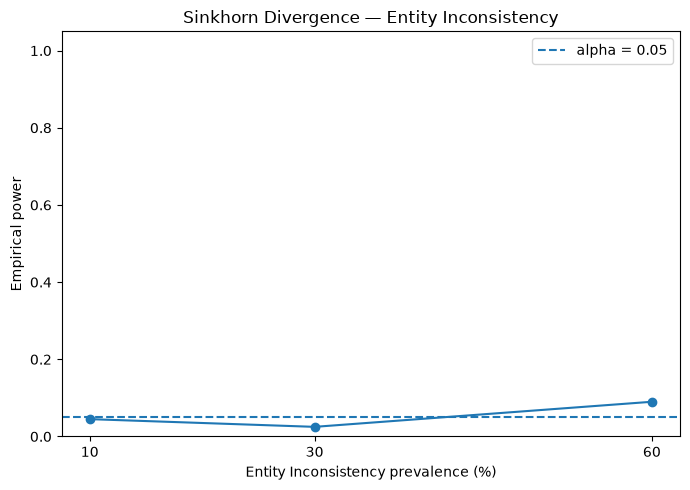

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    entity_sinkhorn_summary["severity"] * 100,
    entity_sinkhorn_summary["power"],
    marker="o"
)

plt.axhline(
    ENTITY_ALPHA,
    linestyle="--",
    label="alpha = 0.05"
)

plt.xlabel("Entity Inconsistency prevalence (%)")
plt.ylabel("Empirical power")
plt.title("Sinkhorn Divergence — Entity Inconsistency")
plt.xticks([10, 30, 60])
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

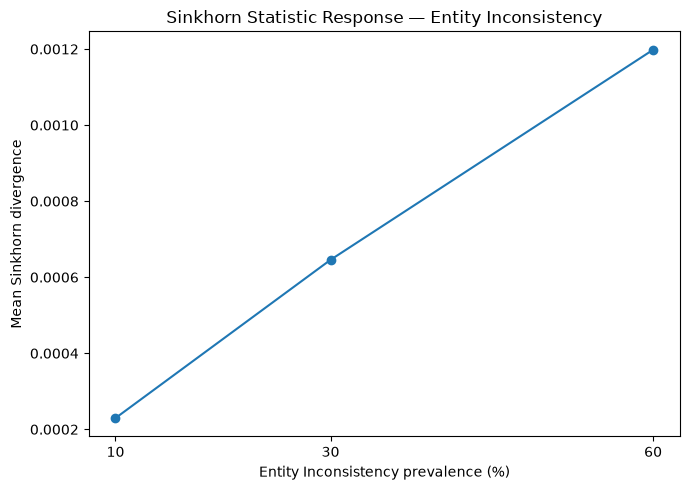

In [54]:
plt.figure(figsize=(7, 5))

plt.plot(
    entity_sinkhorn_summary["severity"] * 100,
    entity_sinkhorn_summary["mean_statistic"],
    marker="o"
)

plt.xlabel("Entity Inconsistency prevalence (%)")
plt.ylabel("Mean Sinkhorn divergence")
plt.title("Sinkhorn Statistic Response — Entity Inconsistency")
plt.xticks([10, 30, 60])
plt.tight_layout()
plt.show()

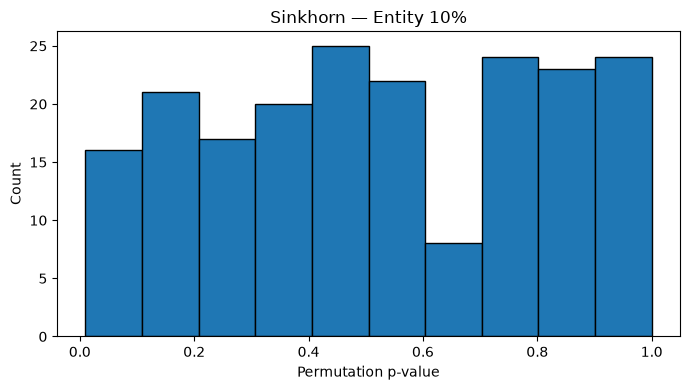

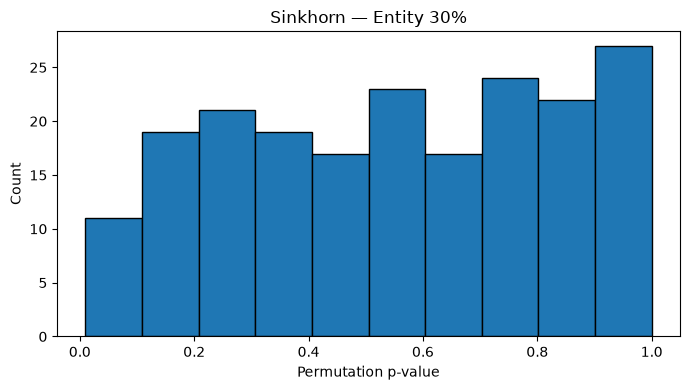

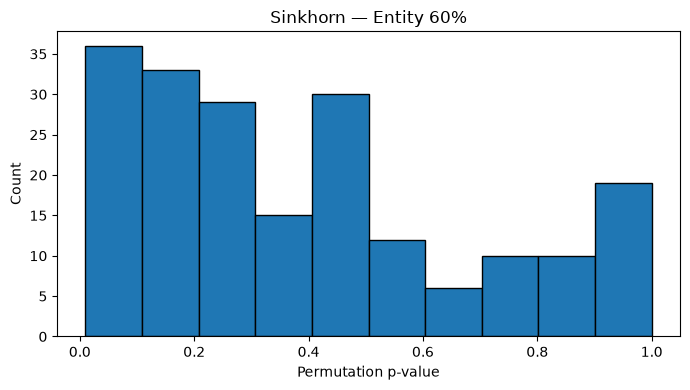

In [55]:
for severity in ENTITY_SEVERITIES:

    subset = entity_sinkhorn_runs.loc[
        np.isclose(
            entity_sinkhorn_runs["severity"],
            severity
        )
    ]

    plt.figure(figsize=(7, 4))

    plt.hist(
        subset["p_value"],
        bins=10,
        edgecolor="black"
    )

    plt.xlabel("Permutation p-value")
    plt.ylabel("Count")
    plt.title(
        f"Sinkhorn — Entity {severity:.0%}"
    )

    plt.tight_layout()
    plt.show()

In [56]:
entity_sinkhorn_runs.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_entity_power_runs.csv",
    index=False
)

entity_sinkhorn_summary.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_entity_power_summary.csv",
    index=False
)

entity_prevalence_check.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_entity_sample_prevalence.csv",
    index=False
)

print("Entity Sinkhorn results saved.")

Entity Sinkhorn results saved.


In [57]:
import json

entity_sinkhorn_config = {
    "defect": "Entity Inconsistency",
    "representation":
        "campaign semantic MiniLM embeddings",
    "embedding_dimension": 384,

    "repetitions": ENTITY_REPS,
    "pairs_per_repetition": ENTITY_N_PAIRS,
    "permutations": ENTITY_PERMUTATIONS,
    "alpha": ENTITY_ALPHA,

    "severities": ENTITY_SEVERITIES,

    "paired_design": True,
    "permutation_scheme":
        "within-pair random swaps",

    "sinkhorn_p": 2,
    "sinkhorn_blur":
        CAMPAIGN_SINKHORN_BLUR,
    "sinkhorn_debiased": True,
    "sinkhorn_backend": "tensorized",
    "device": "cpu",

    "sampling_seed_base":
        ENTITY_SAMPLE_BASE_SEED,
    "test_seed_base":
        ENTITY_TEST_BASE_SEED
}

with open(
    WEEK7_RESULTS_DIR /
    "sinkhorn_entity_configuration.json",
    "w"
) as f:
    json.dump(
        entity_sinkhorn_config,
        f,
        indent=4
    )

print("Entity Sinkhorn configuration saved.")

Entity Sinkhorn configuration saved.


In [58]:
# diagnosis - blind spot?
entity_sinkhorn_runs["obs_minus_null"] = (
    entity_sinkhorn_runs["statistic"] -
    entity_sinkhorn_runs["null_mean"]
)

entity_null_center_check = (
    entity_sinkhorn_runs
    .groupby("severity")["obs_minus_null"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

display(entity_null_center_check)

,severity,mean,std,min,max
0,0.1,2.376109e-11,6.772908e-11,-1.068111e-10,2.533488e-10
1,0.3,8.218776e-11,1.698337e-10,-1.525041e-10,7.619383e-10
2,0.6,5.202106e-10,7.809943e-10,-5.192123e-10,3.608875e-09


In [59]:
# formal paired null calibration 
PAIRED_NULL_REPS = 200
PAIRED_NULL_PERMUTATIONS = 100
PAIRED_NULL_N_PAIRS = 100
PAIRED_NULL_ALPHA = 0.05

paired_null_records = []

start = perf_counter()

for rep in range(PAIRED_NULL_REPS):
    rng = np.random.default_rng(42000 + rep)

    selected = rng.choice(
        len(X_entity_clean),
        size=2 * PAIRED_NULL_N_PAIRS,
        replace=False
    )

    P_null = X_entity_clean[
        selected[:PAIRED_NULL_N_PAIRS]
    ]

    Q_null = X_entity_clean[
        selected[PAIRED_NULL_N_PAIRS:]
    ]

    result = sinkhorn_paired_permutation_test(
        P_null,
        Q_null,
        blur=CAMPAIGN_SINKHORN_BLUR,
        n_permutations=PAIRED_NULL_PERMUTATIONS,
        seed=52000 + rep,
        alpha=PAIRED_NULL_ALPHA
    )

    paired_null_records.append({
        "repetition": rep,
        "statistic": result["statistic"],
        "p_value": result["p_value"],
        "reject": result["reject"],
        "null_mean": result["null_mean"],
        "null_std": result["null_std"]
    })

    if (rep + 1) % 20 == 0:
        print(f"Completed {rep + 1}/{PAIRED_NULL_REPS}")

paired_null_runtime = perf_counter() - start

sinkhorn_paired_null = pd.DataFrame(
    paired_null_records
)

print(
    "Runtime:",
    round(paired_null_runtime / 60, 2),
    "minutes"
)

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Runtime: 5.09 minutes


In [60]:
sinkhorn_paired_null_summary = pd.DataFrame([{
    "repetitions": len(sinkhorn_paired_null),
    "rejections": int(
        sinkhorn_paired_null["reject"].sum()
    ),
    "type_I_error": sinkhorn_paired_null[
        "reject"
    ].mean(),
    "mean_p_value": sinkhorn_paired_null[
        "p_value"
    ].mean(),
    "median_p_value": sinkhorn_paired_null[
        "p_value"
    ].median(),
    "mean_statistic": sinkhorn_paired_null[
        "statistic"
    ].mean(),
    "std_statistic": sinkhorn_paired_null[
        "statistic"
    ].std(),
    "mean_null_statistic": sinkhorn_paired_null[
        "null_mean"
    ].mean()
}])

display(sinkhorn_paired_null_summary)

,repetitions,rejections,type_I_error,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_null_statistic
0,200,13,0.065,0.493663,0.445545,0.045619,0.001114,0.045578


In [61]:
# can the paired test detect a known signal?
rng = np.random.default_rng(42)

X_pair = rng.normal(
    size=(100, 2)
)

pair_scale = median_pairwise_euclidean_scale(
    X_pair
)

pair_blur = 0.10 * pair_scale

Y_pair = X_pair.copy()
Y_pair[:, 0] += 0.25 * pair_scale

paired_known_answer = (
    sinkhorn_paired_permutation_test(
        X_pair,
        Y_pair,
        blur=pair_blur,
        n_permutations=100,
        seed=42,
        alpha=0.05
    )
)

paired_known_answer

{'statistic': 0.06774488091468811,
 'p_value': 0.009900990099009901,
 'reject': True,
 'null_mean': 0.02263327771797776,
 'null_std': 0.0025644186238153233}

In [62]:
sinkhorn_paired_null.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_paired_formal_null_runs.csv",
    index=False
)

sinkhorn_paired_null_summary.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_paired_formal_null_summary.csv",
    index=False
)

print("Paired Sinkhorn null calibration saved.")

Paired Sinkhorn null calibration saved.


### Sinkhorn Divergence - Entity Inconsistency

Following clean-data calibration, Sinkhorn divergence was evaluated on **Entity Inconsistency** using frozen MiniLM campaign embeddings (`all-MiniLM-L6-v2`, 384D, L2-normalized).

Prior metric performance on this defect established a clear baseline:

| Entity Prevalence | C2ST Power | Energy Power | MMD Power |
| ---: | ---: | ---: | ---: |
| **10%** | 0.000 | 0.605 | 0.640 |
| **30%** | 0.025 | 1.000 | 1.000 |
| **60%** | 0.165 | 1.000 | 1.000 |


## Frozen configuration and paired

The Sinkhorn scale parameter was pre-computed strictly from clean campaign pairwise distances prior to defect evaluation:

$$\text{blur} = 0.10 \times 0.4371995 = 0.04371995$$

### Paired Test Protocol
Because each defective campaign $Q_i$ derives directly from clean campaign $P_i$, evaluations used a paired test design:
* **Sample Unit:** $(P_i, Q_i) = (\text{clean campaign}_i, \text{defective campaign}_i)$
* **Sampling Structure:** 100 campaign pairs per repetition over 200 repetitions across 10%, 30%, and 60% severities.
* **Permutation Scheme:** 100 within-pair swap permutations $((P_i, Q_i) \rightarrow (Q_i, P_i))$, preserving pair-level pairing structure.


## Initial Power Results

The initial empirical detection power of Sinkhorn divergence appeared surprisingly low:

| Entity Prevalence | Sinkhorn Power |
| ---: | ---: |
| **10%** | 0.045 |
| **30%** | 0.025 |
| **60%** | 0.090 |

While MMD and Energy Distance reached 1.000 power by 30% prevalence, Sinkhorn power hovered near the nominal rejection threshold ($\alpha = 0.05$).


## Validation Pipeline of the Paired Test

To confirm whether this was a true metric blind spot rather than a flawed statistical test under paired permutations, three diagnostic checks were executed:

### 1. Paired Null Calibration
Tested on independent clean campaign pairs drawn from clean reference data:
* **Type I Error:** 0.065 (well-calibrated near $\alpha = 0.05$)
* **Mean $p$-value:** 0.494
* **Observed vs. Null Statistic:** $S_{\text{obs}} = 0.045619 \approx E[S_{\text{null}}] = 0.045578$

### 2. Paired Synthetic Shift Test
Tested on point clouds subjected to a uniform directional translation ($Q_i = P_i + \delta$):
* **Result:** $S_{\text{obs}} = 0.0677 \gg E[S_{\text{null}}] = 0.0226$
* **$p$-value:** $0.0099$ (minimum achievable with 100 permutations)
* **Conclusion:** The paired Sinkhorn permutation test effectively detects coherent directional shifts.

### 3. Null Geometry Analysis
Direct comparison of observed versus permutation-null expected statistics across severities:

| Severity | Mean $S_{\text{observed}} - E[S_{\text{permutation}}]$ | Standard Deviation |
| ---: | ---: | ---: |
| **10%** | $2.38 \times 10^{-11}$ | $6.77 \times 10^{-11}$ |
| **30%** | $8.22 \times 10^{-11}$ | $1.70 \times 10^{-10}$ |
| **60%** | $5.20 \times 10^{-10}$ | $7.81 \times 10^{-10}$ |

*Interpretation:* The observed Sinkhorn statistic is numerically identical to the center of its own permutation distribution ($S_{\text{obs}} \approx E[S_{\text{perm}}]$).


While the absolute Sinkhorn statistic increased with defect prevalence ($0.000230 \rightarrow 0.000646 \rightarrow 0.001198$), the permutation null distribution shifted upward at the exact same rate.

* **Local Perturbations:** Entity Inconsistency causes small, heterogeneous, localized displacement per campaign ($\approx 0.063$ mean Euclidean distance at 10% prevalence) rather than a coherent global direction.
* **Permutation Invariance:** Reversing localized pairs via within-pair swaps $((x_i^{\text{clean}}, x_i^{\text{defect}}) \rightarrow (x_i^{\text{defect}}, x_i^{\text{clean}}))$ preserves the local distance landscape. The overall transport cost remains nearly invariant under permutation swaps.


## Cross-Metric comparison 

Under identical experimental conditions (data, representation, sample size, and severity):

| Severity | C2ST Power | Energy Power | MMD Power | Sinkhorn Power |
| ---: | ---: | ---: | ---: | ---: |
| **10%** | 0.000 | 0.605 | 0.640 | **0.045** |
| **30%** | 0.025 | 1.000 | 1.000 | **0.025** |
| **60%** | 0.165 | 1.000 | 1.000 | **0.090** |


## Conclusion

Under the frozen MiniLM representation, selected regularization scale ($\text{blur} = 0.04372$), sample size ($N=100$), and within-pair permutation design, **Entity Inconsistency constitutes a metric-specific geometric blind spot for Sinkhorn divergence**.

This finding reinforces a core architectural principle:

$$\text{Larger Statistic Value} \neq \text{Stronger Statistical Evidence}$$

Statistical detection relies not on absolute discrepancy size, but on how unusual the observed discrepancy is relative to its null distribution. Detectability is not an intrinsic property of the defect alone, but emerges from the interaction:

$$\text{Defect} \times \text{Representation} \times \text{Metric} \times \text{Sampling Design} \times \text{Null Construction}$$

##### Missing cross-channel reference



In [63]:
MISSING_REPS = 200
MISSING_N_PAIRS = 100
MISSING_PERMUTATIONS = 100
MISSING_ALPHA = 0.05

MISSING_SEVERITIES = [0.10, 0.30, 0.60]
MISSING_FILE_PERCENTAGES = (10, 30, 60)

MISSING_SAMPLE_BASE_SEED = 42
MISSING_TEST_BASE_SEED = 10000


In [64]:
print("Frozen blur:", CAMPAIGN_SINKHORN_BLUR)

Frozen blur: 0.043719952430236554


In [65]:
# load embeddings 
missing_embeddings = load_embedding_conditions(
    DATA_DIR,
    prefix="missing_reference",
    severities=MISSING_FILE_PERCENTAGES
)

missing_ids = load_id_file(
    DATA_DIR,
    "missing_reference_embedding_campaign_ids.csv",
    id_column="campaign_id"
)

print("Clean:", missing_embeddings["clean"].shape)

for severity in MISSING_SEVERITIES:
    print(
        f"{severity:.0%}:",
        missing_embeddings[severity].shape
    )

print("IDs:", len(missing_ids))
print("Keys:", missing_embeddings.keys())

Clean: (300, 384)
10%: (300, 384)
30%: (300, 384)
60%: (300, 384)
IDs: 300
Keys: dict_keys(['clean', 0.1, 0.3, 0.6])


In [ ]:
# verify alignment and embeddings and norms
X_missing_clean = missing_embeddings["clean"]

assert len(missing_ids) == len(X_missing_clean)
assert len(set(missing_ids)) == len(missing_ids)

for severity in MISSING_SEVERITIES:
    X_def = missing_embeddings[severity]

    assert X_def.shape == X_missing_clean.shape
    assert np.isfinite(X_def).all()

print("Missing-reference embedding alignment passed.")

Missing-reference embedding alignment passed.


In [67]:
for condition, X in missing_embeddings.items():
    norms = np.linalg.norm(X, axis=1)

    print(
        condition,
        "| mean norm =", round(norms.mean(), 6),
        "| min =", round(norms.min(), 6),
        "| max =", round(norms.max(), 6)
    )

clean | mean norm = 1.0 | min = 1.0 | max = 1.0
0.1 | mean norm = 1.0 | min = 1.0 | max = 1.0
0.3 | mean norm = 1.0 | min = 1.0 | max = 1.0
0.6 | mean norm = 1.0 | min = 1.0 | max = 1.0


In [68]:
# verify the clean set matches with entity
print(
    "Same campaign IDs as Entity:",
    np.array_equal(
        np.asarray(missing_ids),
        np.asarray(entity_ids)
    ))

print(
    "Same clean embeddings as Entity:",
    np.allclose(
        X_missing_clean,
        X_entity_clean,
        atol=1e-8
    ))

print(
    "Maximum clean embedding difference:",
    np.max(
        np.abs(
            X_missing_clean -
            X_entity_clean
        )))

Same campaign IDs as Entity: True
Same clean embeddings as Entity: True
Maximum clean embedding difference: 0.0


In [69]:
# load affected ids
missing_affected = load_affected_ids_by_severity(
    DATA_DIR / "missing_reference_affected_campaign_ids.csv",
    id_column="campaign_id"
)

for severity in MISSING_SEVERITIES:
    print(
        f"{severity:.0%}",
        "| affected campaigns =",
        len(missing_affected[severity])
    )

10% | affected campaigns = 30
30% | affected campaigns = 90
60% | affected campaigns = 180


In [70]:
# nested verification
missing_affected_10 = set(
    missing_affected[0.10])

missing_affected_30 = set(
    missing_affected[0.30])

missing_affected_60 = set(
    missing_affected[0.60])

print(
    "10 ⊆ 30:",
    missing_affected_10.issubset(
        missing_affected_30
    ))

print(
    "30 ⊆ 60:",
    missing_affected_30.issubset(
        missing_affected_60
    ))

assert missing_affected_10.issubset(
    missing_affected_30)

assert missing_affected_30.issubset(
    missing_affected_60)

10 ⊆ 30: True
30 ⊆ 60: True


In [71]:
# smoke test
rng = np.random.default_rng(
    MISSING_SAMPLE_BASE_SEED
)

sample_idx = rng.choice(
    len(missing_ids),
    size=MISSING_N_PAIRS,
    replace=False
)

P_smoke = X_missing_clean[
    sample_idx
]

Q_smoke = missing_embeddings[0.10][
    sample_idx
]

start = perf_counter()

missing_smoke = (
    sinkhorn_paired_permutation_test(
        P_smoke,
        Q_smoke,
        blur=CAMPAIGN_SINKHORN_BLUR,
        n_permutations=MISSING_PERMUTATIONS,
        seed=MISSING_TEST_BASE_SEED,
        alpha=MISSING_ALPHA
    )
)

missing_smoke_runtime = (
    perf_counter() - start
)

print(missing_smoke)

print(
    "Runtime:",
    round(missing_smoke_runtime, 2),
    "seconds"
)

{'statistic': 0.0015332705806940794, 'p_value': 0.21782178217821782, 'reject': False, 'null_mean': 0.0015261802065651864, 'null_std': 5.683828243942304e-06}
Runtime: 4.03 seconds


In [72]:
# full experiment
missing_sinkhorn_records = []

start = perf_counter()

for rep in range(MISSING_REPS):

    rng = np.random.default_rng(
        MISSING_SAMPLE_BASE_SEED + rep
    )

    sample_idx = rng.choice(
        len(missing_ids),
        size=MISSING_N_PAIRS,
        replace=False
    )

    sampled_ids = np.asarray(
        missing_ids
    )[sample_idx]

    P = X_missing_clean[
        sample_idx
    ]

    for severity in MISSING_SEVERITIES:

        Q = missing_embeddings[
            severity
        ][sample_idx]

        affected_set = set(
            missing_affected[
                severity
            ]
        )

        n_affected = sum(
            campaign_id in affected_set
            for campaign_id in sampled_ids
        )

        result = (
            sinkhorn_paired_permutation_test(
                P,
                Q,
                blur=CAMPAIGN_SINKHORN_BLUR,
                n_permutations=MISSING_PERMUTATIONS,
                seed=MISSING_TEST_BASE_SEED + rep,
                alpha=MISSING_ALPHA
            )
        )

        missing_sinkhorn_records.append({
            "repetition": rep,
            "severity": severity,
            "n_pairs": MISSING_N_PAIRS,
            "n_affected": n_affected,
            "sample_affected_rate":
                n_affected / MISSING_N_PAIRS,
            "statistic":
                result["statistic"],
            "p_value":
                result["p_value"],
            "reject":
                result["reject"],
            "null_mean":
                result["null_mean"],
            "null_std":
                result["null_std"]
        })

    if (rep + 1) % 20 == 0:
        elapsed = (
            perf_counter() - start)

        print(
            f"Completed {rep + 1}/{MISSING_REPS}",
            "| elapsed:",
            round(elapsed / 60, 1),
            "min")

missing_sinkhorn_runtime = (
    perf_counter() - start)

missing_sinkhorn_runs = pd.DataFrame(
    missing_sinkhorn_records)

print()
print(
    "Rows:",
    len(missing_sinkhorn_runs))

print(
    "Expected:",
    MISSING_REPS *
    len(MISSING_SEVERITIES))

print(
    "Total runtime:",
    round(
        missing_sinkhorn_runtime / 60,
        2
    ),"minutes")

Completed 20/200 | elapsed: 4.1 min
Completed 40/200 | elapsed: 5.4 min
Completed 60/200 | elapsed: 8.4 min
Completed 80/200 | elapsed: 12.6 min
Completed 100/200 | elapsed: 13.9 min
Completed 120/200 | elapsed: 16.4 min
Completed 140/200 | elapsed: 17.5 min
Completed 160/200 | elapsed: 18.5 min
Completed 180/200 | elapsed: 19.7 min
Completed 200/200 | elapsed: 20.7 min

Rows: 600
Expected: 600
Total runtime: 20.74 minutes


In [73]:
# prevalence check
missing_prevalence_check = (
    missing_sinkhorn_runs
    .groupby("severity")
    .agg(
        mean_affected=(
            "n_affected",
            "mean"),
        std_affected=(
            "n_affected",
            "std"),
        min_affected=(
            "n_affected",
            "min"),
        max_affected=(
            "n_affected",
            "max"),
        mean_sample_rate=(
            "sample_affected_rate",
            "mean"))
    .reset_index())

display(missing_prevalence_check)

,severity,mean_affected,std_affected,min_affected,max_affected,mean_sample_rate
0,0.1,10.190,2.394277,3,16,0.10190
1,0.3,30.180,3.899182,19,41,0.30180
2,0.6,60.245,4.220669,50,72,0.60245


In [74]:
missing_sinkhorn_summary = (
    missing_sinkhorn_runs
    .groupby("severity")
    .agg(
        repetitions=(
            "reject",
            "size"),
        rejections=(
            "reject",
            "sum"),
        power=(
            "reject",
            "mean"),
        mean_p_value=(
            "p_value",
            "mean"),
        median_p_value=(
            "p_value",
            "median"),
        mean_statistic=(
            "statistic",
            "mean"),
        std_statistic=(
            "statistic",
            "std"),
        mean_null_statistic=(
            "null_mean",
            "mean"),
        mean_affected=(
            "n_affected",
            "mean"),
        mean_sample_affected_rate=(
            "sample_affected_rate",
            "mean"
        ))
    .reset_index())

display(missing_sinkhorn_summary)

,severity,repetitions,rejections,power,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_null_statistic,mean_affected,mean_sample_affected_rate
0,0.1,200,25,0.125,0.370396,0.247525,0.001771,0.000787,0.001683,10.190,0.10190
1,0.3,200,62,0.310,0.278465,0.158416,0.003714,0.000956,0.003564,30.180,0.30180
2,0.6,200,137,0.685,0.096584,0.029703,0.007810,0.001435,0.007106,60.245,0.60245


In [75]:
# observed - permutation null
missing_sinkhorn_runs[
    "obs_minus_null"] = (missing_sinkhorn_runs["statistic"] -
    missing_sinkhorn_runs[
        "null_mean"])

missing_null_center_check = (
    missing_sinkhorn_runs
    .groupby("severity")[
        "obs_minus_null"].agg([
        "mean",
        "std",
        "min",
        "max"]).reset_index())

display(missing_null_center_check)

,severity,mean,std,min,max
0,0.1,0.000088,0.000158,-0.000005,0.000801
1,0.3,0.000150,0.000214,-0.000011,0.001132
2,0.6,0.000704,0.000668,-0.000013,0.002943


In [76]:
# relative difference 
missing_sinkhorn_runs[
    "relative_excess"] = (
    missing_sinkhorn_runs[
        "statistic"]
    - missing_sinkhorn_runs[
        "null_mean"]) / missing_sinkhorn_runs[
    "null_mean"]

missing_relative_check = (
    missing_sinkhorn_runs
    .groupby("severity")[
        "relative_excess"].agg([
        "mean",
        "std",
        "median"
    ]).reset_index())

display(missing_relative_check)

,severity,mean,std,median
0,0.1,0.037797,0.066187,0.004325
1,0.3,0.036367,0.049789,0.008317
2,0.6,0.093274,0.084890,0.073220


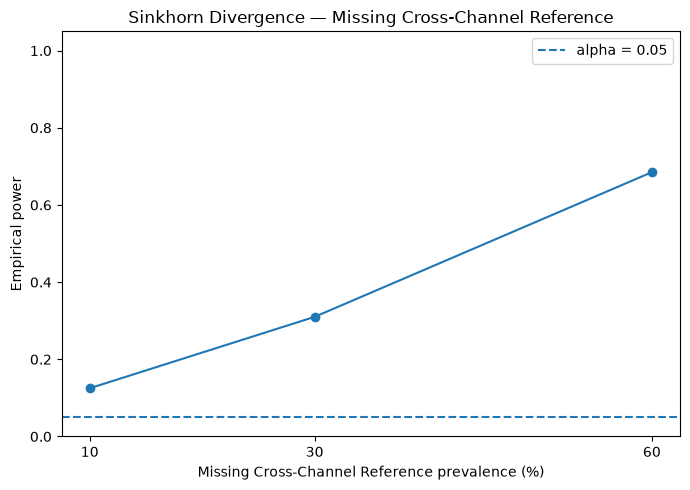

In [77]:
plt.figure(figsize=(7, 5))

plt.plot(
    missing_sinkhorn_summary[
        "severity"] * 100,
    missing_sinkhorn_summary[
        "power"],
    marker="o")

plt.axhline(
    MISSING_ALPHA,
    linestyle="--",
    label="alpha = 0.05")

plt.xlabel("Missing Cross-Channel Reference prevalence (%)")

plt.ylabel("Empirical power")

plt.title("Sinkhorn Divergence — Missing Cross-Channel Reference")

plt.xticks([10, 30, 60])

plt.ylim(0,1.05)

plt.legend()
plt.tight_layout()
plt.show()

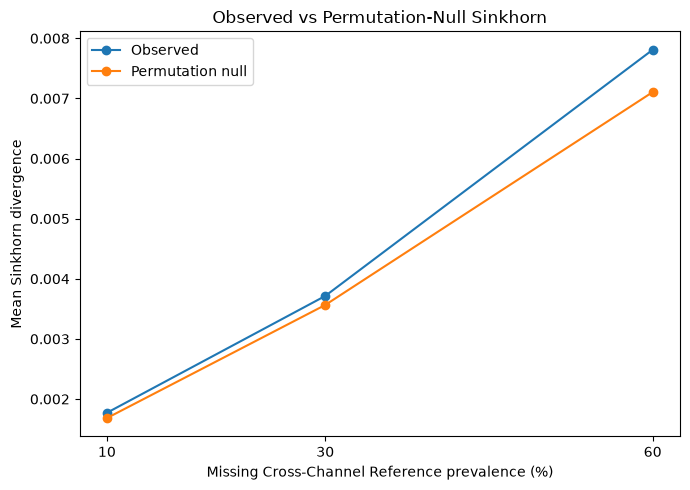

In [78]:
# statistic vs permutation null
plt.figure(figsize=(7, 5))

plt.plot(missing_sinkhorn_summary[
        "severity"] * 100,
    missing_sinkhorn_summary["mean_statistic"],
    marker="o",
    label="Observed")

plt.plot(
    missing_sinkhorn_summary[
        "severity"] * 100,
    missing_sinkhorn_summary[
        "mean_null_statistic"],
    marker="o",
    label="Permutation null")

plt.xlabel("Missing Cross-Channel Reference prevalence (%)")

plt.ylabel("Mean Sinkhorn divergence")

plt.title("Observed vs Permutation-Null Sinkhorn")

plt.xticks([10, 30, 60])

plt.legend()
plt.tight_layout()
plt.show()

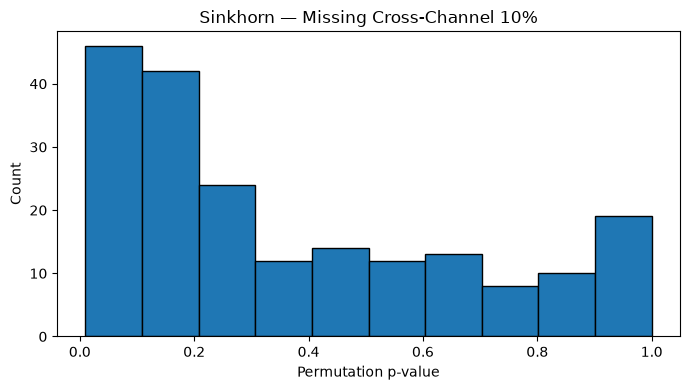

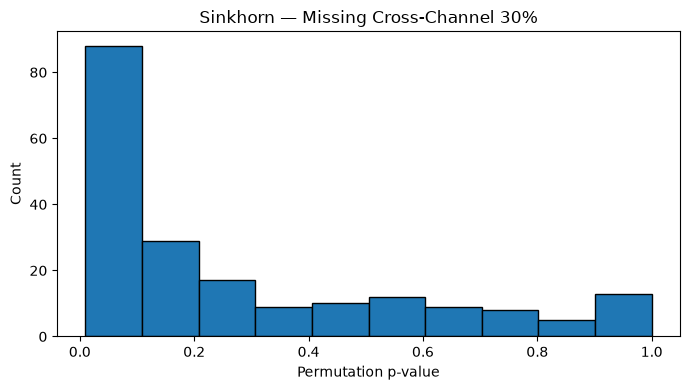

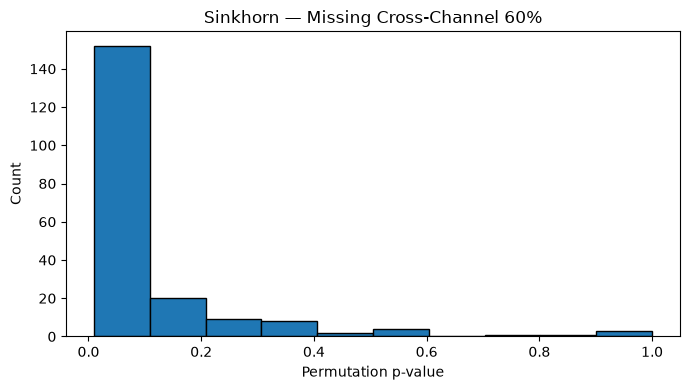

In [79]:
# p values distribution
for severity in MISSING_SEVERITIES:

    subset = (
        missing_sinkhorn_runs.loc[
            np.isclose(
                missing_sinkhorn_runs[
                    "severity"
                ],
                severity)])

    plt.figure(figsize=(7, 4))

    plt.hist(
        subset["p_value"],
        bins=10,
        edgecolor="black")

    plt.xlabel(
        "Permutation p-value")

    plt.ylabel("Count")

    plt.title(f"Sinkhorn — Missing Cross-Channel {severity:.0%}")

    plt.tight_layout()
    plt.show()

In [80]:
# entity vs missing comparison 
sinkhorn_defect_comparison = pd.DataFrame({
    "severity": MISSING_SEVERITIES,
    "entity_power": [
        entity_sinkhorn_summary.loc[
            np.isclose(
                entity_sinkhorn_summary[
                    "severity"
                ],
                s
            ),
            "power"
        ].iloc[0]
        for s in MISSING_SEVERITIES
    ],
    "missing_power": [
        missing_sinkhorn_summary.loc[
            np.isclose(
                missing_sinkhorn_summary[
                    "severity"
                ],
                s
            ),
            "power"
        ].iloc[0]
        for s in MISSING_SEVERITIES
    ]
})

display(
    sinkhorn_defect_comparison
)

,severity,entity_power,missing_power
0,0.1,0.045,0.125
1,0.3,0.025,0.310
2,0.6,0.090,0.685


In [81]:
missing_sinkhorn_runs.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_missing_reference_power_runs.csv",
    index=False)

missing_sinkhorn_summary.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_missing_reference_power_summary.csv",
    index=False)

missing_prevalence_check.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_missing_reference_sample_prevalence.csv",
    index=False)

missing_null_center_check.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_missing_reference_null_center.csv",
    index=False)

sinkhorn_defect_comparison.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_entity_vs_missing.csv",
    index=False)

print("Missing Cross-Channel Sinkhorn results saved.")

Missing Cross-Channel Sinkhorn results saved.


In [82]:
missing_sinkhorn_config = {
    "defect":
        "Missing Cross-Channel Reference",

    "representation":
        "campaign semantic MiniLM embeddings",

    "embedding_dimension":
        384,

    "repetitions":
        MISSING_REPS,

    "pairs_per_repetition":
        MISSING_N_PAIRS,

    "permutations":
        MISSING_PERMUTATIONS,

    "alpha":
        MISSING_ALPHA,

    "severities":
        MISSING_SEVERITIES,

    "paired_design":
        True,

    "permutation_scheme":
        "within-pair random swaps",

    "sinkhorn_p":
        2,

    "sinkhorn_blur":
        CAMPAIGN_SINKHORN_BLUR,

    "sinkhorn_debiased":
        True,

    "sinkhorn_backend":
        "tensorized",

    "device":
        "cpu",

    "sampling_seed_base":
        MISSING_SAMPLE_BASE_SEED,

    "test_seed_base":
        MISSING_TEST_BASE_SEED
}

with open(
    WEEK7_RESULTS_DIR /
    "sinkhorn_missing_reference_configuration.json",
    "w") as f:

    json.dump(
        missing_sinkhorn_config,
        f,
        indent=4)

print("Missing Cross-Channel Sinkhorn configuration saved.")

Missing Cross-Channel Sinkhorn configuration saved.


### Missing-Cross Channel Reference

This evaluation tested the frozen Sinkhorn configuration on Missing-cross channel reference to determine its statistical detectability under a paired experimental design. Unlike Entity inconsistency—which exhibited near-null power due to pair-swap invariance—Missing-cross channel reference systematically broke permutation invariance, causing the observed transport geometry to separate from the null distribution as defect prevalence increased.


#### Key findings

* **Increasing empirical power:** Sinkhorn power scaled monotonically with defect prevalence:
  * 10% prevalence: 0.125
  * 30% prevalence: 0.310
  * 60% prevalence: 0.685
* **Growing observed-null gap:** The observed Sinkhorn statistic ($S_{\text{observed}}$) separated progressively from the expected permutation-null statistic ($E[S_{\text{null}}]$):
  * 10% prevalence: mean excess of 0.000088
  * 30% prevalence: mean excess of 0.000150
  * 60% prevalence: mean excess of 0.000704
* **Substantial embedding displacement:** Affected-pair Euclidean displacement averaged approximately 0.159 at 10% prevalence, 0.137 at 30%, and 0.140 at 60%.


#### Comparison with other metrics

While Sinkhorn showed strong sensitivity to Missing-cross channel reference, its power growth rate differed across alternative metrics:

* **Energy and MMD:** Both metrics outperformed Sinkhorn at higher prevalences, achieving 0.550 and 0.560 at 30% prevalence, and reaching 0.995 at 60% prevalence.
* **Linear C2ST:** C2ST exhibited lower power than Sinkhorn across higher severities, yielding 0.125 at 30% prevalence and 0.505 at 60% prevalence.
* **Low-prevalence similarity:** At 10% prevalence, Sinkhorn (0.125), Energy (0.140), and MMD (0.140) exhibited similar baseline performance.


* **Breakdown of pair-swap invariance:** Randomly reversing clean and defective pair orientations $(P_i, Q_i) \rightarrow (Q_i, P_i)$ systematically altered the transport geometry. This disruption caused the observed discrepancy to be consistently larger than the expected null statistic.
* **Absence of a general Sinkhorn blind spot:** The paired Sinkhorn test is not inherently insensitive to small semantic defects. Detectability depends on whether a defect reorders distributional geometry in a manner disrupted by within-pair permutation.
* **Separation of representation move from detectability:** Average displacement magnitude alone does not dictate statistical power. Detectability arises from how coherent geometric perturbations look under the metric's specific null construction.

#### Over polished language - Sinkhorn

In [83]:
importlib.reload(io_utils)
importlib.reload(metrics)

from src.io_utils import (
    load_embedding_conditions,
    load_id_file,
    load_affected_ids_by_severity
)

from src.metrics import (
    median_pairwise_euclidean_scale,
    sinkhorn_divergence,
    sinkhorn_paired_permutation_test
)

OP_REPS = 200
OP_N_PAIRS = 100
OP_PERMUTATIONS = 100
OP_ALPHA = 0.05

OP_SEVERITIES = [0.10, 0.30, 0.60]
OP_FILE_PERCENTAGES = (10, 30, 60)

OP_SAMPLE_BASE_SEED = 42
OP_TEST_BASE_SEED = 10000

In [84]:
# load 700 reference embeddings 
OP_reference_embeddings = np.load(
    DATA_DIR / "over_polished_reference_embeddings.npy"
)

OP_reference_ids = load_id_file(
    DATA_DIR,
    "over_polished_reference_embedding_message_ids.csv",
    id_column="message_id"
)

print("Reference embeddings:", OP_reference_embeddings.shape)
print("Reference IDs:", len(OP_reference_ids))
print(
    "Mean norm:",
    np.linalg.norm(OP_reference_embeddings, axis=1).mean()
)

Reference embeddings: (700, 384)
Reference IDs: 700
Mean norm: 1.0


In [85]:
# sms specific sinkhorn blur 
OP_CLEAN_GEOMETRIC_SCALE = median_pairwise_euclidean_scale(
    OP_reference_embeddings
)

OP_SINKHORN_BLUR_FRACTION = 0.10

OP_SINKHORN_BLUR = (
    OP_SINKHORN_BLUR_FRACTION *
    OP_CLEAN_GEOMETRIC_SCALE
)

print(
    "SMS median clean pairwise distance:",
    OP_CLEAN_GEOMETRIC_SCALE
)

print(
    "Frozen SMS Sinkhorn blur:",
    OP_SINKHORN_BLUR
)

SMS median clean pairwise distance: 1.3281227117017558
Frozen SMS Sinkhorn blur: 0.13281227117017558


In [86]:
# identity check
OP_identity = OP_reference_embeddings[:100]

op_identity_value = sinkhorn_divergence(
    OP_identity,
    OP_identity,
    blur=OP_SINKHORN_BLUR)

print(
    "SMS S(X, X):",
    f"{op_identity_value:.12e}")

SMS S(X, X): 0.000000000000e+00


In [87]:
# clean and defective evaluation embeddings 
op_embeddings = load_embedding_conditions(
    DATA_DIR,
    prefix="over_polished",
    severities=OP_FILE_PERCENTAGES
)

op_ids = load_id_file(
    DATA_DIR,
    "over_polished_embedding_message_ids.csv",
    id_column="message_id"
)

X_op_clean = op_embeddings["clean"]

print("Clean:", X_op_clean.shape)

for severity in OP_SEVERITIES:
    print(
        f"{severity:.0%}:",
        op_embeddings[severity].shape
    )

print("IDs:", len(op_ids))
print("Keys:", op_embeddings.keys())

Clean: (300, 384)
10%: (300, 384)
30%: (300, 384)
60%: (300, 384)
IDs: 300
Keys: dict_keys(['clean', 0.1, 0.3, 0.6])


In [88]:
assert len(op_ids) == len(X_op_clean)
assert len(set(op_ids)) == len(op_ids)

for condition, X in op_embeddings.items():
    assert X.shape == (300, 384)
    assert np.isfinite(X).all()

    norms = np.linalg.norm(X, axis=1)

    print(
        condition,
        "| mean norm =", round(norms.mean(), 6),
        "| min =", round(norms.min(), 6),
        "| max =", round(norms.max(), 6)
    )

print("Over-Polished embedding validation passed.")

clean | mean norm = 1.0 | min = 1.0 | max = 1.0
0.1 | mean norm = 1.0 | min = 1.0 | max = 1.0
0.3 | mean norm = 1.0 | min = 1.0 | max = 1.0
0.6 | mean norm = 1.0 | min = 1.0 | max = 1.0
Over-Polished embedding validation passed.


In [89]:
# labels ham / spam
op_split = pd.read_csv(
    DATA_DIR / "over_polished_sms_split.csv"
)

op_eval_meta = (
    op_split.loc[
        op_split["split"] == "evaluation",
        ["message_id", "label"]
    ]
    .set_index("message_id")
    .loc[op_ids]
    .reset_index()
)

print(op_eval_meta.shape)
print(op_eval_meta["label"].value_counts())

(300, 2)
label
ham     260
spam     40
Name: count, dtype: int64


In [90]:
import src.io_utils as io_utils

importlib.reload(io_utils)

from src.io_utils import (
    stratified_disjoint_pair_indices)

In [91]:
# validate clean paired sampler
p_idx, q_idx = stratified_disjoint_pair_indices(
    op_eval_meta["label"].to_numpy(),
    n_pairs=OP_N_PAIRS,
    seed=42)

print("P:", len(p_idx))
print("Q:", len(q_idx))

print(
    "Overlap:",
    len(set(p_idx) & set(q_idx)))

print("\nP labels:")
print(
    op_eval_meta.iloc[p_idx][
        "label"
    ].value_counts())

print("\nQ labels:")
print(
    op_eval_meta.iloc[q_idx][
        "label"
    ].value_counts())

P: 100
Q: 100
Overlap: 0

P labels:
label
ham     87
spam    13
Name: count, dtype: int64

Q labels:
label
ham     87
spam    13
Name: count, dtype: int64


In [92]:
# paired null calibration 
OP_NULL_REPS = 200
OP_NULL_PERMUTATIONS = 100

op_null_records = []

start = perf_counter()

for rep in range(OP_NULL_REPS):

    p_idx, q_idx = (
        stratified_disjoint_pair_indices(
            op_eval_meta[
                "label"
            ].to_numpy(),
            n_pairs=OP_N_PAIRS,
            seed=42000 + rep))

    P_null = X_op_clean[
        p_idx]

    Q_null = X_op_clean[
        q_idx]

    result = (
        sinkhorn_paired_permutation_test(
            P_null,
            Q_null,
            blur=OP_SINKHORN_BLUR,
            n_permutations=OP_NULL_PERMUTATIONS,
            seed=52000 + rep,
            alpha=OP_ALPHA))

    op_null_records.append({
        "repetition": rep,
        "statistic":
            result["statistic"],
        "p_value":
            result["p_value"],
        "reject":
            result["reject"],
        "null_mean":
            result["null_mean"],
        "null_std":
            result["null_std"]
    })

    if (rep + 1) % 20 == 0:
        print(
            f"Completed {rep + 1}/{OP_NULL_REPS}")

op_null_runtime = (
    perf_counter() - start)

op_sinkhorn_paired_null = pd.DataFrame(
    op_null_records)

print(
    "Runtime:",
    round(
        op_null_runtime / 60, 2),"minutes")

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Runtime: 9.61 minutes


In [93]:
op_sinkhorn_null_summary = pd.DataFrame([{
    "repetitions":
        len(op_sinkhorn_paired_null),

    "rejections":
        int(
            op_sinkhorn_paired_null[
                "reject"
            ].sum()
        ),

    "type_I_error":
        op_sinkhorn_paired_null[
            "reject"
        ].mean(),

    "mean_p_value":
        op_sinkhorn_paired_null[
            "p_value"
        ].mean(),

    "median_p_value":
        op_sinkhorn_paired_null[
            "p_value"
        ].median(),

    "mean_statistic":
        op_sinkhorn_paired_null[
            "statistic"
        ].mean(),

    "std_statistic":
        op_sinkhorn_paired_null[
            "statistic"
        ].std(),

    "mean_null_statistic":
        op_sinkhorn_paired_null[
            "null_mean"
        ].mean()
}])

display(
    op_sinkhorn_null_summary
)

,repetitions,rejections,type_I_error,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_null_statistic
0,200,10,0.05,0.484307,0.480198,0.606511,0.008664,0.605964


In [94]:
op_sinkhorn_paired_null.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_over_polished_paired_null_runs.csv",
    index=False)

op_sinkhorn_null_summary.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_over_polished_paired_null_summary.csv",
    index=False)


In [95]:
op_affected = load_affected_ids_by_severity(
    DATA_DIR /
    "over_polished_affected_message_ids.csv",
    id_column="message_id"
)

for severity in OP_SEVERITIES:
    print(
        f"{severity:.0%}",
        "| affected messages =",
        len(op_affected[severity])
    )

10% | affected messages = 30
30% | affected messages = 90
60% | affected messages = 180


In [96]:
op_affected = load_affected_ids_by_severity(
    DATA_DIR /
    "over_polished_affected_message_ids.csv",
    id_column="message_id")

for severity in OP_SEVERITIES:
    print(
        f"{severity:.0%}",
        "| affected messages =",
        len(op_affected[severity]))

10% | affected messages = 30
30% | affected messages = 90
60% | affected messages = 180


In [97]:
# zero displacement blind cases
for severity in OP_SEVERITIES:

    D = np.linalg.norm(
        op_embeddings[severity] -
        X_op_clean,
        axis=1
    )

    affected_mask = np.array([
        message_id in set(
            op_affected[severity]
        )
        for message_id in op_ids
    ])

    affected_distances = D[
        affected_mask
    ]

    print(
        f"{severity:.0%}",
        "| affected =",
        affected_mask.sum(),
        "| zero displacement =",
        np.sum(
            affected_distances <= 1e-8
        )
    )

10% | affected = 30 | zero displacement = 0
30% | affected = 90 | zero displacement = 2
60% | affected = 180 | zero displacement = 7


In [98]:
# over polished power experiment
op_sinkhorn_records = []

start = perf_counter()

for rep in range(OP_REPS):

    rng = np.random.default_rng(
        OP_SAMPLE_BASE_SEED + rep
    )

    sample_idx = rng.choice(
        len(op_ids),
        size=OP_N_PAIRS,
        replace=False
    )

    sampled_ids = np.asarray(
        op_ids
    )[sample_idx]

    P = X_op_clean[
        sample_idx
    ]

    for severity in OP_SEVERITIES:

        Q = op_embeddings[
            severity
        ][sample_idx]

        affected_set = set(
            op_affected[
                severity
            ]
        )

        n_affected = sum(
            message_id in affected_set
            for message_id in sampled_ids
        )

        result = (
            sinkhorn_paired_permutation_test(
                P,
                Q,
                blur=OP_SINKHORN_BLUR,
                n_permutations=OP_PERMUTATIONS,
                seed=OP_TEST_BASE_SEED + rep,
                alpha=OP_ALPHA
            )
        )

        op_sinkhorn_records.append({
            "repetition": rep,
            "severity": severity,
            "n_pairs": OP_N_PAIRS,
            "n_affected": n_affected,
            "sample_affected_rate":
                n_affected / OP_N_PAIRS,
            "statistic":
                result["statistic"],
            "p_value":
                result["p_value"],
            "reject":
                result["reject"],
            "null_mean":
                result["null_mean"],
            "null_std":
                result["null_std"]
        })

    if (rep + 1) % 20 == 0:
        elapsed = (
            perf_counter() - start
        )

        print(
            f"Completed {rep + 1}/{OP_REPS}",
            "| elapsed:",
            round(
                elapsed / 60,
                1
            ),
            "min"
        )

op_sinkhorn_runtime = (
    perf_counter() - start
)

op_sinkhorn_runs = pd.DataFrame(
    op_sinkhorn_records
)

print(
    "Rows:",
    len(op_sinkhorn_runs)
)

print(
    "Expected:",
    OP_REPS *
    len(OP_SEVERITIES)
)

print(
    "Total runtime:",
    round(
        op_sinkhorn_runtime / 60,
        2
    ),
    "minutes"
)

Completed 20/200 | elapsed: 1.0 min
Completed 40/200 | elapsed: 2.2 min
Completed 60/200 | elapsed: 3.6 min
Completed 80/200 | elapsed: 4.7 min
Completed 100/200 | elapsed: 5.9 min
Completed 120/200 | elapsed: 7.2 min
Completed 140/200 | elapsed: 8.3 min
Completed 160/200 | elapsed: 9.4 min
Completed 180/200 | elapsed: 10.6 min
Completed 200/200 | elapsed: 11.7 min
Rows: 600
Expected: 600
Total runtime: 11.72 minutes


In [99]:
# prevalence 
op_prevalence_check = (
    op_sinkhorn_runs
    .groupby("severity")
    .agg(
        mean_affected=(
            "n_affected",
            "mean"
        ),
        std_affected=(
            "n_affected",
            "std"
        ),
        min_affected=(
            "n_affected",
            "min"
        ),
        max_affected=(
            "n_affected",
            "max"
        ),
        mean_sample_rate=(
            "sample_affected_rate",
            "mean"
        )
    )
    .reset_index()
)

display(
    op_prevalence_check
)

,severity,mean_affected,std_affected,min_affected,max_affected,mean_sample_rate
0,0.1,9.880,2.341584,3,15,0.09880
1,0.3,30.065,3.881508,21,40,0.30065
2,0.6,60.310,3.806091,51,68,0.60310


In [100]:
op_sinkhorn_summary = (
    op_sinkhorn_runs
    .groupby("severity")
    .agg(
        repetitions=(
            "reject",
            "size"
        ),
        rejections=(
            "reject",
            "sum"
        ),
        power=(
            "reject",
            "mean"
        ),
        mean_p_value=(
            "p_value",
            "mean"
        ),
        median_p_value=(
            "p_value",
            "median"
        ),
        mean_statistic=(
            "statistic",
            "mean"
        ),
        std_statistic=(
            "statistic",
            "std"
        ),
        mean_null_statistic=(
            "null_mean",
            "mean"
        ),
        mean_affected=(
            "n_affected",
            "mean"
        ),
        mean_sample_affected_rate=(
            "sample_affected_rate",
            "mean"
        )
    )
    .reset_index()
)

display(
    op_sinkhorn_summary
)

,severity,repetitions,rejections,power,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_null_statistic,mean_affected,mean_sample_affected_rate
0,0.1,200,26,0.130,0.550149,0.603960,0.002211,0.000739,0.002211,9.880,0.09880
1,0.3,200,5,0.025,0.857723,1.000000,0.009951,0.003522,0.009887,30.065,0.30065
2,0.6,200,8,0.040,0.610149,0.524752,0.020655,0.004775,0.019778,60.310,0.60310


In [101]:
# observed minus permutaion null
op_sinkhorn_runs[
    "obs_minus_null"
] = (
    op_sinkhorn_runs[
        "statistic"
    ]
    -
    op_sinkhorn_runs[
        "null_mean"
    ]
)

op_null_center_check = (
    op_sinkhorn_runs
    .groupby("severity")[
        "obs_minus_null"
    ]
    .agg([
        "mean",
        "std",
        "min",
        "max"
    ])
    .reset_index()
)

display(
    op_null_center_check
)

,severity,mean,std,min,max
0,0.1,3.666797e-09,1.221395e-08,-8.707866e-10,6.404705e-08
1,0.3,6.349765e-05,1.938306e-04,-2.834518e-06,7.594880e-04
2,0.6,8.770471e-04,1.228059e-03,-3.662370e-06,4.727196e-03


In [102]:
for _, row in op_sinkhorn_summary.iterrows():

    print(
        f"{row['severity']:.0%}",
        "| power =",
        f"{row['power']:.3f}",
        "| mean statistic =",
        f"{row['mean_statistic']:.6f}",
        "| mean null =",
        f"{row['mean_null_statistic']:.6f}",
        "| mean p =",
        f"{row['mean_p_value']:.4f}",
        "| mean affected =",
        f"{row['mean_affected']:.1f}"
    )

10% | power = 0.130 | mean statistic = 0.002211 | mean null = 0.002211 | mean p = 0.5501 | mean affected = 9.9
30% | power = 0.025 | mean statistic = 0.009951 | mean null = 0.009887 | mean p = 0.8577 | mean affected = 30.1
60% | power = 0.040 | mean statistic = 0.020655 | mean null = 0.019778 | mean p = 0.6101 | mean affected = 60.3


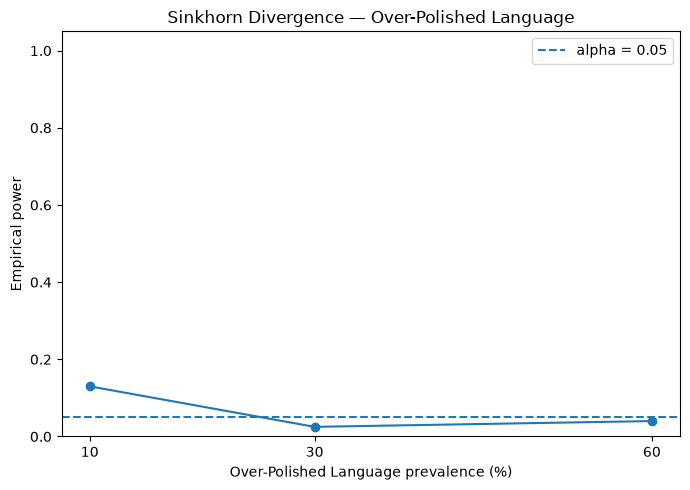

In [103]:
plt.figure(figsize=(7, 5))

plt.plot(
    op_sinkhorn_summary[
        "severity"
    ] * 100,
    op_sinkhorn_summary[
        "power"
    ],
    marker="o"
)

plt.axhline(
    OP_ALPHA,
    linestyle="--",
    label="alpha = 0.05"
)

plt.xlabel(
    "Over-Polished Language prevalence (%)"
)

plt.ylabel(
    "Empirical power"
)

plt.title(
    "Sinkhorn Divergence — Over-Polished Language"
)

plt.xticks(
    [10, 30, 60]
)

plt.ylim(
    0,
    1.05
)

plt.legend()
plt.tight_layout()
plt.show()

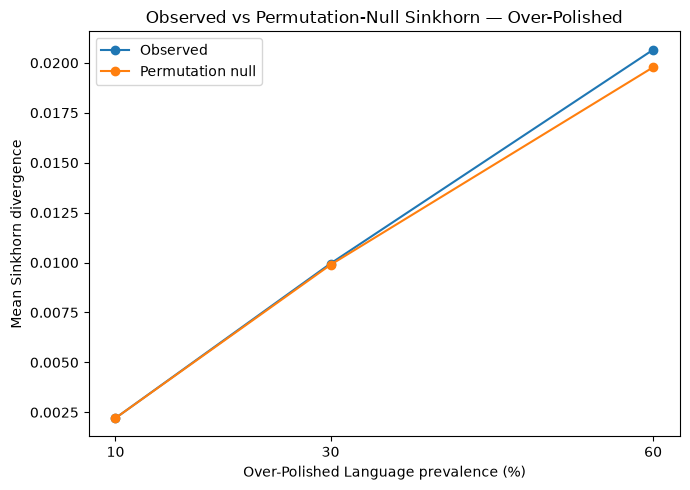

In [104]:
# observed vs permutation null
plt.figure(figsize=(7, 5))

plt.plot(
    op_sinkhorn_summary[
        "severity"
    ] * 100,
    op_sinkhorn_summary[
        "mean_statistic"
    ],
    marker="o",
    label="Observed"
)

plt.plot(
    op_sinkhorn_summary[
        "severity"
    ] * 100,
    op_sinkhorn_summary[
        "mean_null_statistic"
    ],
    marker="o",
    label="Permutation null"
)

plt.xlabel(
    "Over-Polished Language prevalence (%)"
)

plt.ylabel(
    "Mean Sinkhorn divergence"
)

plt.title(
    "Observed vs Permutation-Null Sinkhorn — Over-Polished"
)

plt.xticks(
    [10, 30, 60]
)

plt.legend()
plt.tight_layout()
plt.show()

In [105]:
op_sinkhorn_runs.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_over_polished_power_runs.csv",
    index=False
)

op_sinkhorn_summary.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_over_polished_power_summary.csv",
    index=False
)

op_prevalence_check.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_over_polished_sample_prevalence.csv",
    index=False
)

op_null_center_check.to_csv(
    WEEK7_RESULTS_DIR /
    "sinkhorn_over_polished_null_center.csv",
    index=False
)

print(
    "Over-Polished Sinkhorn results saved."
)

Over-Polished Sinkhorn results saved.


In [106]:
op_sinkhorn_config = {
    "defect":
        "Over-Polished Language",

    "experimental_unit":
        "individual SMS",

    "representation":
        "MiniLM message embeddings",

    "embedding_dimension":
        384,

    "clean_scale_source":
        "700 clean reference SMS embeddings",

    "clean_geometric_scale":
        OP_CLEAN_GEOMETRIC_SCALE,

    "blur_fraction":
        OP_SINKHORN_BLUR_FRACTION,

    "sinkhorn_blur":
        OP_SINKHORN_BLUR,

    "sinkhorn_p":
        2,

    "sinkhorn_debiased":
        True,

    "sinkhorn_backend":
        "tensorized",

    "device":
        "cpu",

    "repetitions":
        OP_REPS,

    "pairs_per_repetition":
        OP_N_PAIRS,

    "permutations":
        OP_PERMUTATIONS,

    "alpha":
        OP_ALPHA,

    "severities":
        OP_SEVERITIES,

    "paired_design":
        True,

    "permutation_scheme":
        "within-pair random swaps",

    "paired_null":
        "independent clean messages paired within ham/spam class",

    "sampling_seed_base":
        OP_SAMPLE_BASE_SEED,

    "test_seed_base":
        OP_TEST_BASE_SEED
}

with open(
    WEEK7_RESULTS_DIR /
    "sinkhorn_over_polished_configuration.json",
    "w"
) as f:

    json.dump(
        op_sinkhorn_config,
        f,
        indent=4
    )

print(
    "Over-Polished Sinkhorn configuration saved."
)

Over-Polished Sinkhorn configuration saved.


In [ ]:
# verify that 384D + SMS geometry + blur=0.1328 + paired test can detect an organized signal

rng = np.random.default_rng(42)

sample_idx = rng.choice(
    len(X_op_clean),
    size=100,
    replace=False
)

P_sms_known = X_op_clean[sample_idx].copy()

# Coherent translation along one embedding dimension
shift_size = 0.25 * OP_CLEAN_GEOMETRIC_SCALE

Q_sms_known = P_sms_known.copy()
Q_sms_known[:, 0] += shift_size

sms_known_answer = sinkhorn_paired_permutation_test(
    P_sms_known,
    Q_sms_known,
    blur=OP_SINKHORN_BLUR,
    n_permutations=100,
    seed=42,
    alpha=0.05
)

print("Shift:", shift_size)
print(sms_known_answer)

Shift: 0.33203067792543894
{'statistic': 0.05512218922376633, 'p_value': 0.009900990099009901, 'reject': True, 'null_mean': 0.05485411554574966, 'null_std': 0.00024229552685773302}


### Over-Polished Language

#### Message-level calibration and configuration changes

* **Message-level experimental unit:** The evaluation operated on individual SMS message embeddings rather than campaign-level aggregations.
* **Clean-derived SMS scale:** A new regularization scale was derived exclusively from 700 clean reference SMS embeddings:
  * Median clean pairwise Euclidean distance: 1.3281227
  * Derived Sinkhorn blur ($0.10 \times \text{median}$): 0.13281227
* **Null calibration:** Under class-matched clean SMS baseline conditions, empirical Type I error was exactly 0.050, confirming the test was properly calibrated without inflated null statistics.
* **Representation-level blind cases:** Stylistic modifications (e.g., capitalization or whitespace) caused zero embedding displacement for 0 messages at 10%, 2 messages at 30%, and 7 messages at 60% prevalence due to identical tokenizer inputs.



#### Key findings

* **Low and non-monotonic power:** Sinkhorn power remained close to baseline rejection levels across severities:
  * 10% prevalence: 0.130
  * 30% prevalence: 0.025
  * 60% prevalence: 0.040
* **Parallel increase in null statistic:** While the raw Sinkhorn statistic grew substantially with prevalence ($0.002211 \rightarrow 0.009951 \rightarrow 0.020655$), the permutation-null statistic increased almost in parallel ($0.002211 \rightarrow 0.009887 \rightarrow 0.019778$).
* **Unstable observed-null gap:** The mean observed minus null excess was effectively zero at 10% ($3.67 \times 10^{-9}$), rising to 0.0000635 at 30% (median p-value of 1.000) and 0.000877 at 60% (SD of 0.001228). High sample variability prevented this average gap from translating into statistical power.
* **Substantial embedding displacement:** Affected-pair Euclidean displacement averaged approximately 0.190 at 10% prevalence, 0.203 at 30%, and 0.207 at 60%.

#### Comparison with other metrics

* **MMD and Energy distance:** Both metrics detected Over-polished language almost perfectly, achieving 0.870 and 0.880 power at 10% prevalence, and reaching 1.000 power at both 30% and 60% prevalence.
* **Linear C2ST:** C2ST exhibited weak power at lower severities (0.000 at 10% and 0.280 at 30%), but became highly sensitive at 60% prevalence (0.930).

#### Implications

* **Large raw discrepancy vs statistical power:** A larger raw transport discrepancy does not guarantee higher detection power if the paired permutation null tracks that increase.
* **Preservation under pair swaps:** Localized, stylistic movements across varying embedding regions remain largely invariant to clean/defective orientation swaps under paired Optimal Transport.
* **Distinct metric regimes:** Across evaluated defects, Sinkhorn exhibited three distinct behaviors:
  * Complete pair-swap invariance with near-zero observed-null gap.
  * Monotonic observed-null separation resulting in high statistical power.
  * Growing raw discrepancy with high null tracking and unstable separation, resulting in weak power.